# 01 · Exploratory Data Analysis

**Business question:** How much of each product family will each store sell over the next 2 weeks, and how can that forecast reduce stockouts and excess inventory?

**Data:** Corporación Favorita (Ecuadorian grocery chain), Jan 2013 – Aug 2017: 54 stores × 33 product families, daily sales, plus promotions, holidays, oil prices and store metadata.

This notebook looks for the patterns a forecasting model will need to learn.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)

RAW = "../data/raw/"
train = pd.read_csv(RAW + "train.csv", parse_dates=["date"])
stores = pd.read_csv(RAW + "stores.csv")
oil = pd.read_csv(RAW + "oil.csv", parse_dates=["date"])
holidays = pd.read_csv(RAW + "holidays_events.csv", parse_dates=["date"])

print(train.shape)
train.head()

Matplotlib is building the font cache; this may take a moment.


(3000888, 6)


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


## 1. Data quality checks

In [2]:
print("Date range:", train.date.min().date(), "to", train.date.max().date())
print("Stores:", train.store_nbr.nunique(), "| Families:", train.family.nunique())
print("Missing values:\n", train.isna().sum())

all_days = pd.date_range(train.date.min(), train.date.max())
print("Dates with no records:", list(all_days.difference(train.date.unique()).date))
print(f"Share of rows with zero sales: {(train.sales == 0).mean():.1%}")

Date range: 2013-01-01 to 2017-08-15
Stores: 54 | Families: 33
Missing values:
 id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64
Dates with no records: [datetime.date(2013, 12, 25), datetime.date(2014, 12, 25), datetime.date(2015, 12, 25), datetime.date(2016, 12, 25)]
Share of rows with zero sales: 31.3%


**Takeaway:** The data is clean: no missing values. The only missing dates are Christmas Day (stores closed). About 31% of rows have zero sales, mostly families a store doesn't stock, so the model has to handle many zeros.

## 2. Overall sales trend

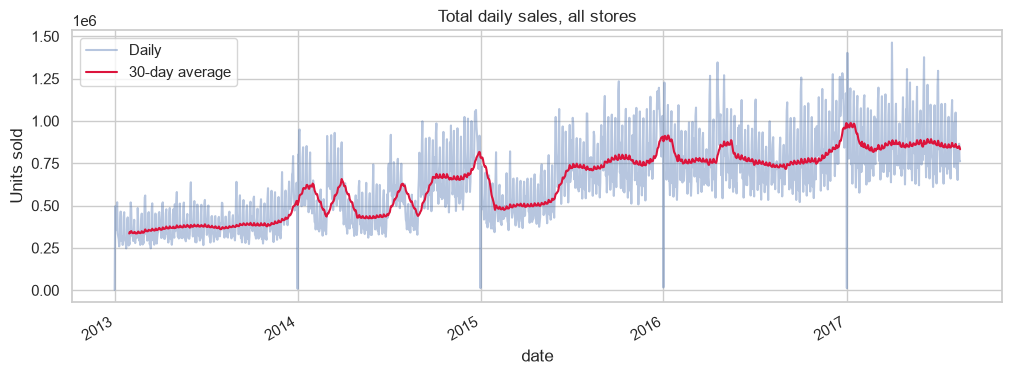

In [3]:
daily = train.groupby("date").sales.sum()

ax = daily.plot(alpha=0.4, label="Daily")
daily.rolling(30).mean().plot(ax=ax, color="crimson", label="30-day average")
ax.set_title("Total daily sales, all stores")
ax.set_ylabel("Units sold")
ax.legend();

In [4]:
yearly = daily.groupby(daily.index.year).agg(["sum", "count"])
yearly["avg_per_day"] = yearly["sum"] / yearly["count"]
yearly.round(0)

,sum,count,avg_per_day
date,,,
2013,140419014.0,364,385767.0
2014,209474246.0,364,575479.0
2015,240880101.0,364,661759.0
2016,288654523.0,365,790834.0
2017,194217068.0,227,855582.0


**Takeaway:** Sales grow steadily year over year (average daily sales roughly doubled from 2013 to 2017). Each year also drops sharply on 1 January. A model needs a sense of trend, and should be validated on the most recent period.

## 3. Seasonality: day of week and month

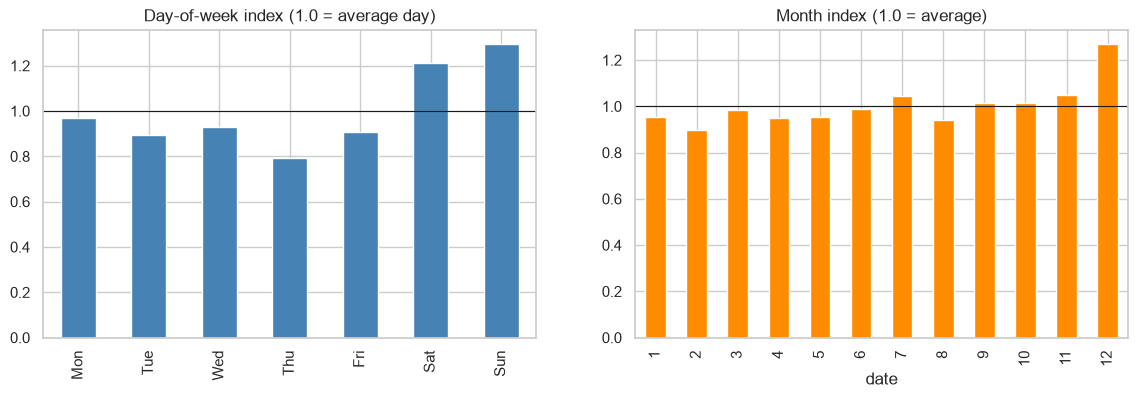

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

dow = daily.groupby(daily.index.day_of_week).mean() / daily.mean()
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dow.plot.bar(ax=axes[0], color="steelblue")
axes[0].axhline(1, color="k", lw=0.8)
axes[0].set_title("Day-of-week index (1.0 = average day)")

month = daily.groupby(daily.index.month).mean() / daily.mean()
month.plot.bar(ax=axes[1], color="darkorange")
axes[1].axhline(1, color="k", lw=0.8)
axes[1].set_title("Month index (1.0 = average)");

**Takeaway:** Weekends are about 20–30% above an average day, and Thursday is the quietest. December is about 27% above average (holiday shopping). Day of week and month will be strong features.

## 4. Which product families matter?

Top 5 families = 79% of all sales


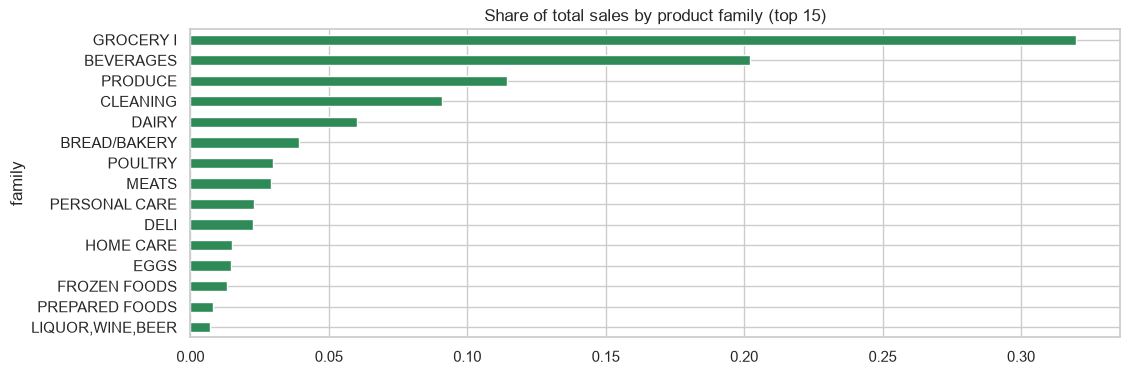

In [6]:
share = train.groupby("family").sales.sum().sort_values(ascending=False) / train.sales.sum()
share.head(15).plot.barh(color="seagreen").invert_yaxis()
plt.title("Share of total sales by product family (top 15)")
print(f"Top 5 families = {share.head(5).sum():.0%} of all sales")

**Takeaway:** Sales are concentrated: GROCERY I, BEVERAGES, PRODUCE, CLEANING and DAIRY make up most of the volume. Errors on these families cost the most, so they get extra attention in the evaluation.

## 5. Store types

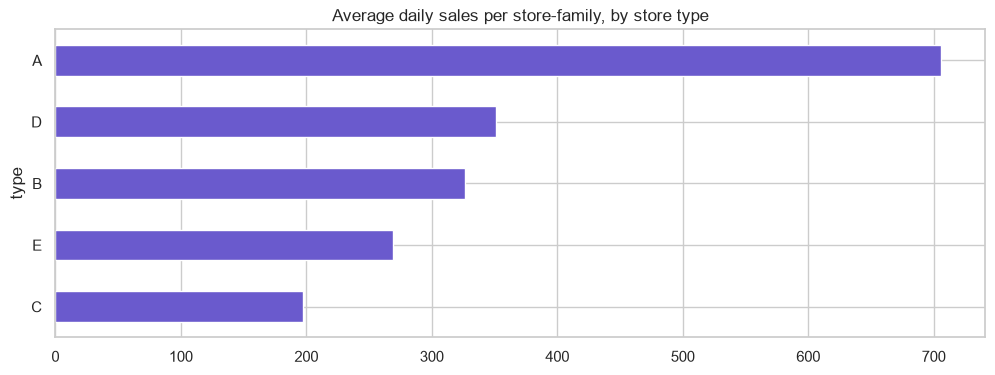

In [7]:
m = train.merge(stores, on="store_nbr")
m.groupby("type").sales.mean().sort_values().plot.barh(color="slateblue")
plt.title("Average daily sales per store-family, by store type");

**Takeaway:** Type A stores sell roughly 2–3× more than other types. Store attributes (type, cluster, city) help the model tell stores apart.

## 6. Promotions

Median sales, raw comparison:
promo
False     25.647499
True     373.000000
Name: sales, dtype: float64


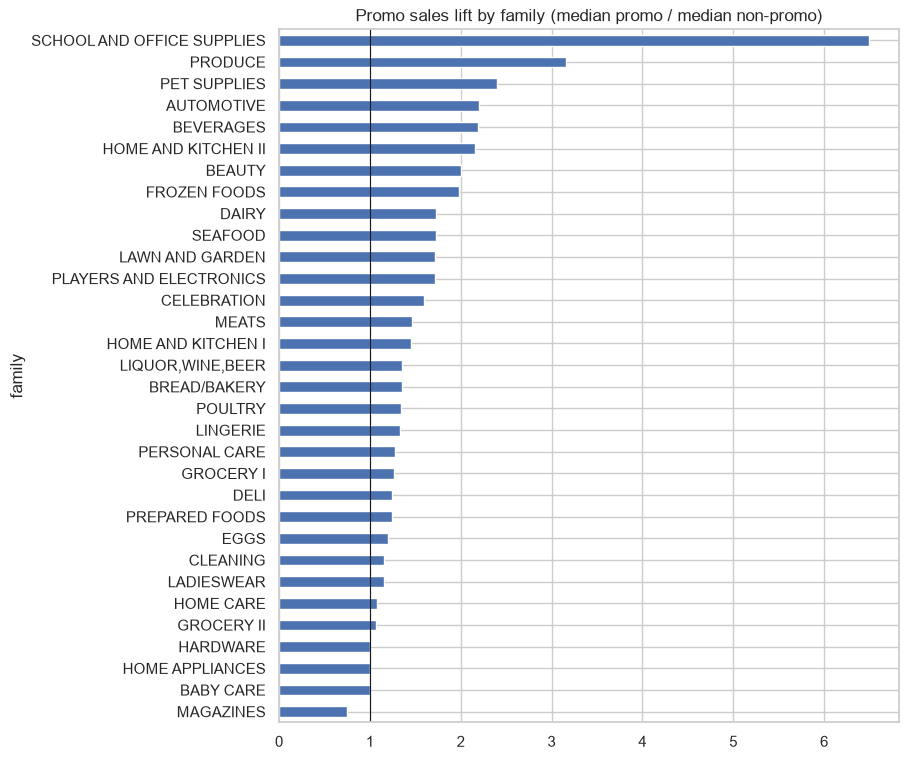

In [8]:
sold = train[train.sales > 0].copy()
sold["promo"] = sold.onpromotion > 0
print("Median sales, raw comparison:")
print(sold.groupby("promo").sales.median())

# Fairer comparison: within the same family
by_fam = sold.groupby(["family", "promo"]).sales.median().unstack()
by_fam["lift"] = by_fam[True] / by_fam[False]
by_fam["lift"].dropna().sort_values().plot.barh(figsize=(8, 9))
plt.axvline(1, color="k", lw=0.8)
plt.title("Promo sales lift by family (median promo / median non-promo)");

**Takeaway:** The raw comparison is misleading. Promotions mostly run on high-volume families, which makes the gap look huge. Comparing within each family gives a more honest lift, and it's still above 1 for most families. Promotions are a useful feature, and they're known in advance, so we can use them when forecasting.

## 7. Holidays and oil price

In [9]:
nat = holidays[(holidays.locale == "National") & (holidays.transferred == False)]
is_hol = daily.index.isin(nat.date)
print(f"Avg sales on national holidays: {daily[is_hol].mean():,.0f}")
print(f"Avg sales on other days:        {daily[~is_hol].mean():,.0f}")

Avg sales on national holidays: 747,263
Avg sales on other days:        627,918


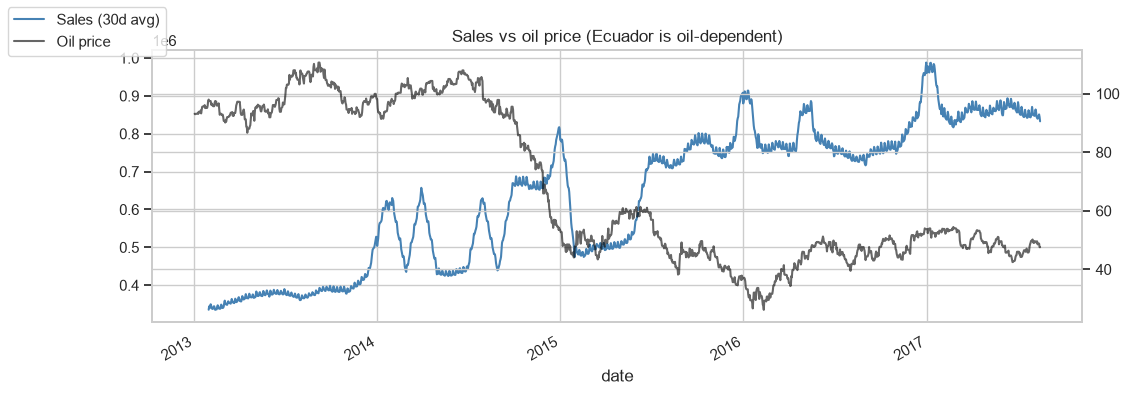

In [10]:
o = oil.set_index("date").dcoilwtico.reindex(daily.index).ffill()
fig, ax1 = plt.subplots()
daily.rolling(30).mean().plot(ax=ax1, color="steelblue", label="Sales (30d avg)")
ax2 = ax1.twinx()
o.plot(ax=ax2, color="black", alpha=0.6, label="Oil price")
ax1.set_title("Sales vs oil price (Ecuador is oil-dependent)")
fig.legend(loc="upper left");

**Takeaway:** National holidays shift demand. Oil prices fell sharply in late 2014 while sales kept growing, so oil adds context rather than a strong direct signal. We'll test it as a feature and keep it only if it helps.

## Summary: what the model needs

| Pattern | Feature to build |
|---|---|
| Strong weekly cycle | day of week |
| December peak, 1 Jan dip | month, day of year, holiday flags |
| Upward trend | recent sales levels (lags, rolling averages) |
| Big differences between stores and families | store/family IDs, store type, cluster |
| Promotion lift | `onpromotion` (known in advance) |
| Many zeros | model has to handle intermittent demand |

**Next:** `02_baselines_and_model.ipynb`: simple baselines first, then LightGBM.